# nb07 · 五个通用势函数的 L0–L5 量化排名

**目的**：把 `results/models/<key>/` 下五个模型的 L0–L5 结果画出来，让排名的每一分都能追到具体的物理量。

被测模型（`mlipeval/models.py`）：

| key | 模型 | 训练数据的理论水平 | dtype |
|---|---|---|---|
| `mace_mpa0` | MACE-MPA-0 (medium) | PBE+U (MPtrj + sAlex) | float64 |
| `nequip_oam_l` | NequIP-OAM-L 0.1 | PBE / PBE+U (OMat24 + MPtrj + sAlex) | float64 |
| `dpa4_pro` | DPA-4.0.1-Pro-MPtrj | PBE+U (MPtrj) | float64 |
| `mattersim_5m` | MatterSim v1 5M | PBE (MPtrj + 有限温/压内部集) | float32 |
| `chgnet_030` | CHGNet 0.3.0 | PBE / PBE+U (MPtrj) | float32 |

**分数的含义**（详见 `mlipeval/ranking.py`）：逐指标 `100 × (x_best + floor) / (x_i + floor)`，
最好的模型 100 分，误差是它两倍的约 50 分。`floor` 是该量的物理/统计分辨尺度，
低于它的差异不计分。这是**相对**排名，不是框架第 4 节的 A/B/C/F 绝对判级——
两者并存：

- **相对排名**（本 notebook 的主线）：同一套参考对五个模型的偏置是共同的，名次不受参考噪声影响；
- **绝对判级**：L3–L5 的每个 canonical 状态点有 3 条独立 AIMD 副本，`sigma_ref` 取副本之间的 RMS，
  于是这些级别第一次有了 A/B/C/F（第 9 节）；L0–L2 的参考是逐结构一个 DFT 标签，没有副本，
  仍只用于相对排名。所有参考都是 phase-1 canonical 协议，`d_protocol = 0`。

**本 notebook 不做任何计算**，只读 `results/models/` 的 JSON 与 `data/models/` 的 npz，
可以直接在登录节点打开。图内文字一律英文，叙述用中文（与 nb01–nb06 一致）。

In [1]:
import os
# per-model results/data (results/models/<key>/); without it mlipeval falls back to the
# flat pre-2026-09 layout, which no longer holds current results
os.environ.setdefault("MLIPEVAL_MODEL", "mace_mpa0")
import sys, json
sys.path.insert(0, "../scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from mlipeval import crossmodel as cm
from mlipeval import paths
from mlipeval.plotting import use_style
from mlipeval.ranking import LEVELS, build_ranking

use_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 60)

MODELS = cm.available_models()
LABELS = {k: cm.label(k) for k in MODELS}

ranking = build_ranking(MODELS)
ORDER = ranking.order()                      # best first, used by every figure
print("models with results:", ", ".join(LABELS[k] for k in MODELS))
print("ranking order      :", ", ".join(LABELS[k] for k in ORDER))
print("level weights      :", ranking.level_weights)

models with results: MACE-MPA-0 (medium), NequIP-OAM-L 0.1, DPA-4.0.1-Pro-MPtrj, MatterSim v1 5M, CHGNet 0.3.0
ranking order      : NequIP-OAM-L 0.1, DPA-4.0.1-Pro-MPtrj, MACE-MPA-0 (medium), MatterSim v1 5M, CHGNet 0.3.0
level weights      : {'L0': 0.2, 'L1': 0.15, 'L2': 0.15, 'L3': 0.25, 'L4': 0.15, 'L5': 0.1}


## 1. 总排名

左图是加权总分，右图把它拆成六级——每行一个模型（按名次排），每列一级，
列标题带该级权重。格内是该级得分，**100 表示该级最好的模型**（得分是逐指标相对折算的，
所以每列必有一个 100）。

**读法**：总分接近不代表画像相同，沿行扫一眼就能看出每个模型赢在哪一级、输在哪一级。
色标是**单色深浅**而不是红-黄-绿：得分是纯粹的大小，50 分不代表「中性」而是「误差约为最好模型的两倍」，
红-黄-绿会在 50 处造出一条数据里并不存在的分界。

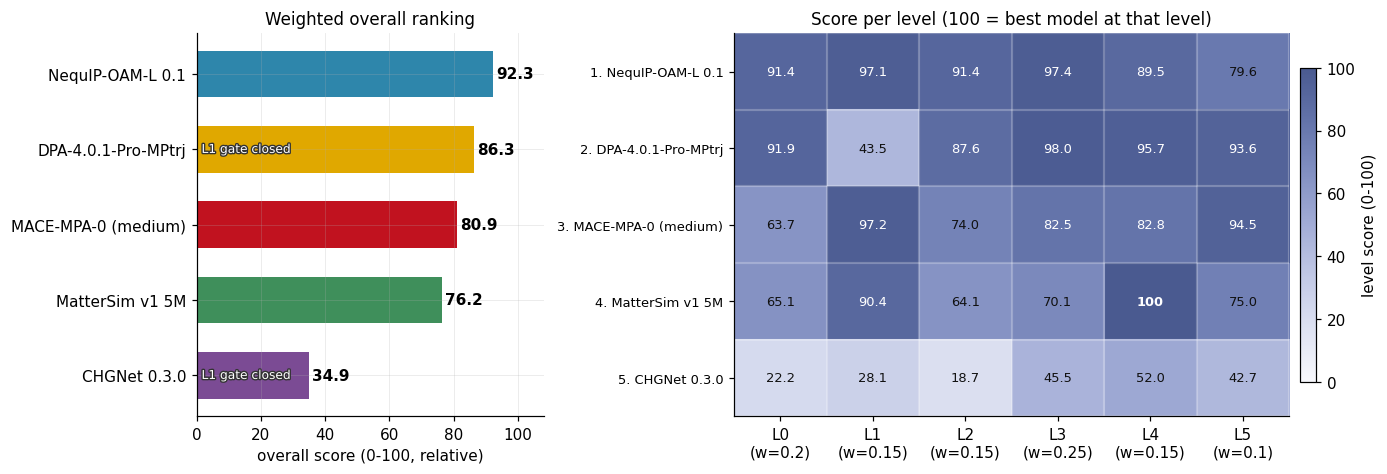

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), width_ratios=[1, 1.6])

# --- overall score ---------------------------------------------------------
ax = axes[0]
y = np.arange(len(ORDER))[::-1]
vals = [ranking.overall[k] for k in ORDER]
bars = ax.barh(y, vals, color=[cm.color(k) for k in ORDER], height=0.62)
for yi, v, k in zip(y, vals, ORDER):
    ax.text(v + 1.0, yi, f"{v:.1f}", va="center", fontsize=10, fontweight="bold")
    if not ranking.gate_open[k]:
        # white on the amber bar is unreadable; outline the text instead of
        # picking a colour per bar
        txt = ax.text(1.5, yi, "L1 gate closed", va="center", fontsize=8, color="white")
        txt.set_path_effects([pe.withStroke(linewidth=1.8, foreground="#333333")])
ax.set_yticks(y)
ax.set_yticklabels([LABELS[k] for k in ORDER])
ax.set_xlim(0, 108)
ax.set_xlabel("overall score (0-100, relative)")
ax.set_title("Weighted overall ranking")

# --- per level -------------------------------------------------------------
# A heatmap, not five grouped bar series: 30 bars in 6 clusters makes the reader
# hop between a legend and a cluster to answer "where is this model weak", while
# a matrix answers it by scanning one row.  Model identity moves to the row
# labels, so the cells are free to carry magnitude on a single sequential ramp.
ax = axes[1]
level_mat = np.array([[ranking.level_scores[lv][k] or np.nan for lv in LEVELS]
                      for k in ORDER])

im = ax.imshow(level_mat, cmap=cm.SCORE_CMAP, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(LEVELS)))
ax.set_xticklabels([f"{lv}\n(w={ranking.level_weights[lv]:g})" for lv in LEVELS])
ax.set_yticks(range(len(ORDER)))
ax.set_yticklabels([f"{i}. {LABELS[k]}" for i, k in enumerate(ORDER, 1)], fontsize=8.5)
# 1px white gaps: the cells are a table, and a continuous field would invite
# reading a gradient across levels that does not exist
ax.set_xticks(np.arange(-0.5, len(LEVELS), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(ORDER), 1), minor=True)
ax.grid(which="minor", color="white", lw=1.4)
ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)

for i, k in enumerate(ORDER):
    for j, lv in enumerate(LEVELS):
        v = level_mat[i, j]
        if not np.isfinite(v):
            continue
        # 100 is the per-level winner by construction of the score, so it is worth
        # marking as a fact rather than leaving the reader to spot the darkest cell
        ax.text(j, i, f"{v:.0f}" if v >= 99.95 else f"{v:.1f}",
                ha="center", va="center", fontsize=8.5,
                fontweight="bold" if v >= 99.95 else "normal",
                color=cm.score_ink(v))
ax.set_title("Score per level (100 = best model at that level)")
fig.colorbar(im, ax=ax, shrink=0.82, pad=0.02, label="level score (0-100)")
plt.show()

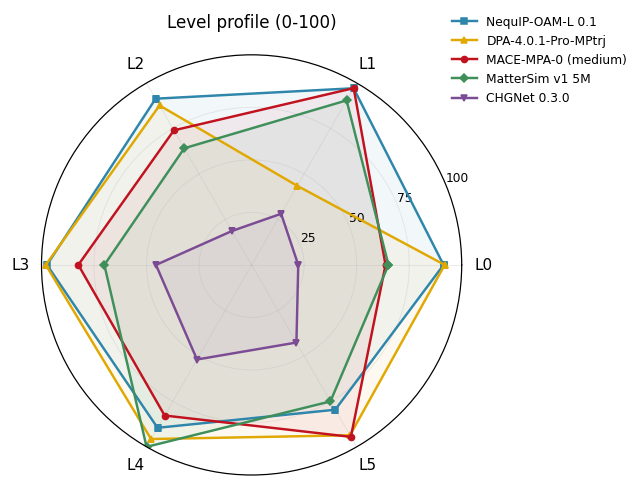

In [3]:
# radar: the same six numbers, but as a shape -- easier to see *what kind* of
# model each one is than to read five grouped bars
angles = np.linspace(0, 2 * np.pi, len(LEVELS), endpoint=False)
closed = np.concatenate([angles, angles[:1]])

fig, ax = plt.subplots(figsize=(5.6, 5.6), subplot_kw=dict(projection="polar"))
for k in ORDER:
    vals = np.array([ranking.level_scores[lv][k] or 0.0 for lv in LEVELS])
    ax.plot(closed, np.concatenate([vals, vals[:1]]), color=cm.color(k),
            marker=cm.marker(k), ms=4, lw=1.6, label=LABELS[k])
    ax.fill(closed, np.concatenate([vals, vals[:1]]), color=cm.color(k), alpha=0.06)
ax.set_xticks(angles)
ax.set_xticklabels(LEVELS)
ax.set_ylim(0, 100)
ax.set_yticks([25, 50, 75, 100])
ax.set_yticklabels(["25", "50", "75", "100"], fontsize=8)
ax.set_title("Level profile (0-100)", pad=18)
ax.legend(loc="upper right", bbox_to_anchor=(1.42, 1.12), fontsize=8)
plt.show()

## 2. 逐指标得分热图

逐指标 × 5 个模型。每格是该指标的相对得分，格内数字是**原始值**。
一行里必有一个 100 分（该指标的最好模型）。空格表示这个模型缺该指标。

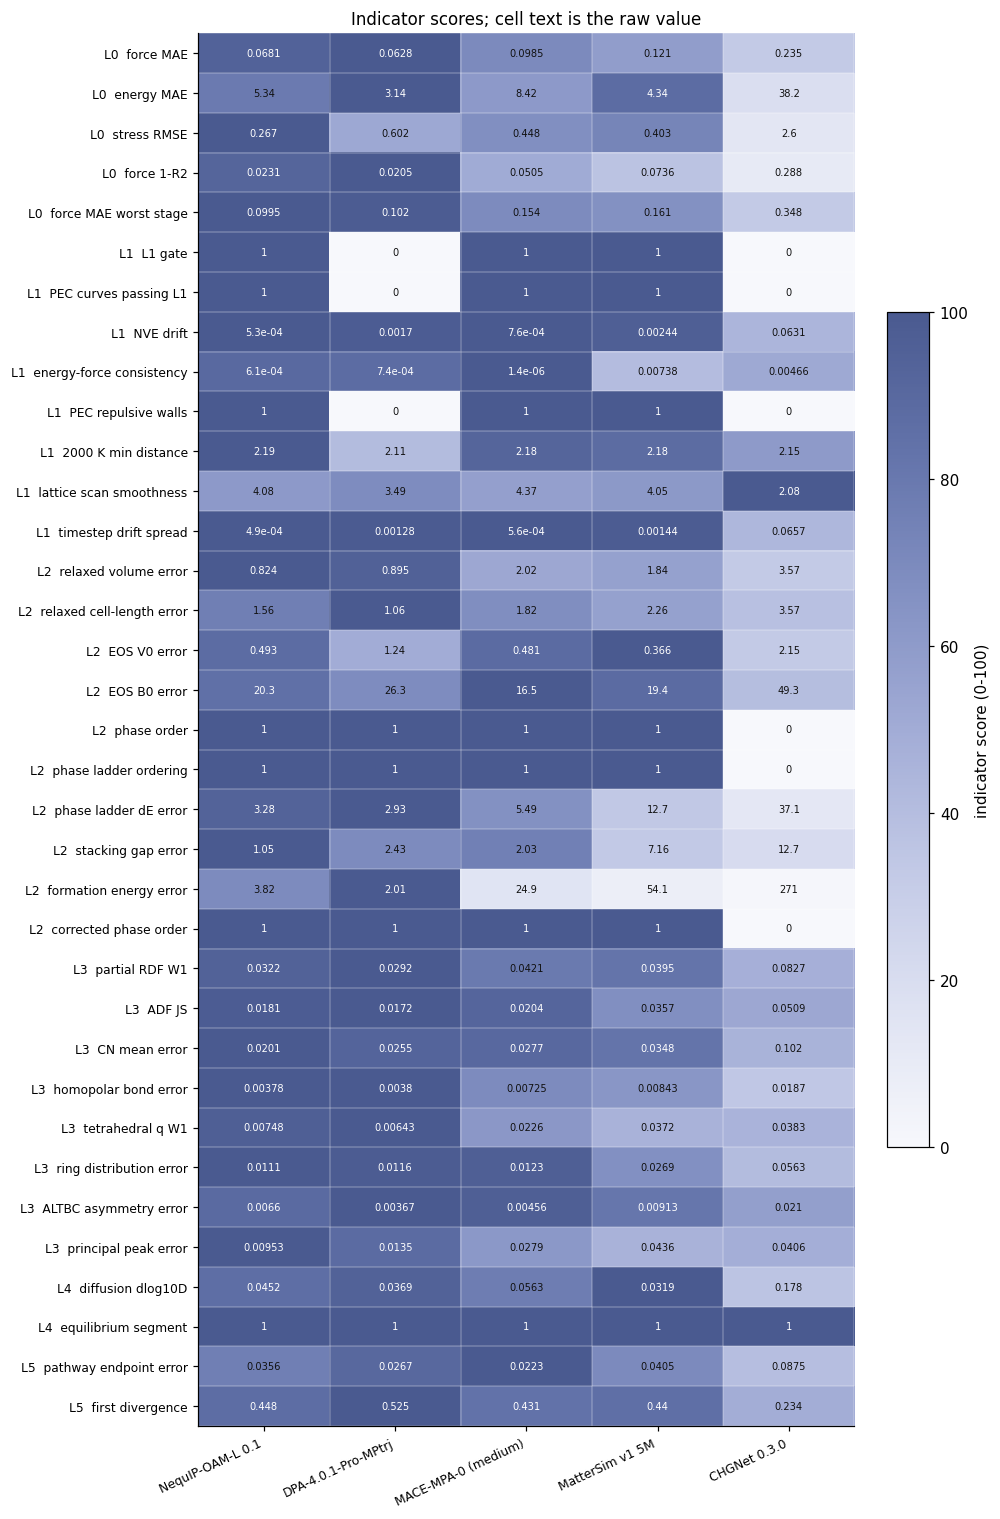

In [4]:
rows = [r for r in ranking.rows if any(v is not None for v in r.score.values())]
mat = np.full((len(rows), len(ORDER)), np.nan)
for i, row in enumerate(rows):
    for j, k in enumerate(ORDER):
        if row.score[k] is not None:
            mat[i, j] = row.score[k]

fig, ax = plt.subplots(figsize=(9.0, 0.34 * len(rows) + 1.8))
im = ax.imshow(mat, cmap=cm.SCORE_CMAP, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(ORDER)))
ax.set_xticklabels([LABELS[k] for k in ORDER], rotation=25, ha="right", fontsize=8)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{r.indicator.level}  {r.indicator.key}" for r in rows], fontsize=8)
ax.set_xticks(np.arange(-0.5, len(ORDER), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(rows), 1), minor=True)
ax.grid(which="minor", color="white", lw=1.0)
ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)

for i, row in enumerate(rows):
    for j, k in enumerate(ORDER):
        raw = row.raw[k]
        if raw is None:
            continue
        txt = f"{raw:.3g}" if abs(raw) >= 1e-3 or raw == 0 else f"{raw:.1e}"
        ax.text(j, i, txt, ha="center", va="center", fontsize=6.5,
                color=cm.score_ink(mat[i, j]))
fig.colorbar(im, ax=ax, shrink=0.6, label="indicator score (0-100)")
ax.set_title("Indicator scores; cell text is the raw value")
plt.show()

## 3. L0 — 对 H5（120 帧 canonical 重算）的静态精度

H5 是从 L3–L5 用的同一批 canonical AIMD 链上抽的 120 帧（950 K、升温、3000 K 熔体、1200 K 液体、
淬火、300 K 非晶），用 canonical 静态协议重新算的单点，角色 `protected_audit`。
能量已按 `database_link.md` 3.4 逐组成去掉常数偏移，所以跨模型可比；力和应力本来就与能量零点无关。

（这一级的结论在执行后填写。）

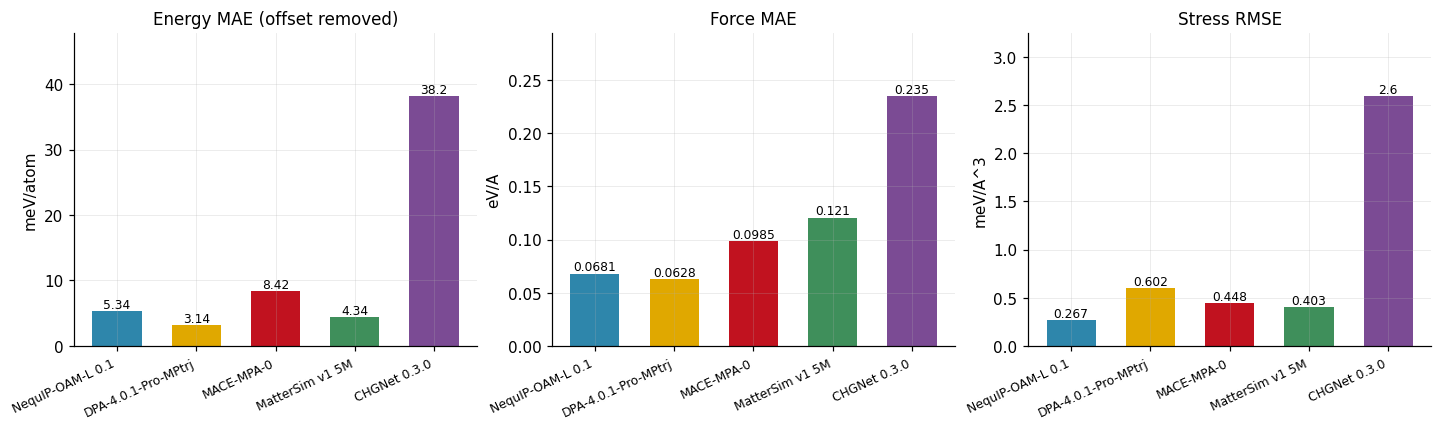

In [5]:
def bar_panel(ax, metric_id, files, title, unit, logy=False):
    df = cm.metric_table(ORDER, f"^{metric_id.replace('.', chr(92) + '.')}$", files)
    vals = {r["model"]: r["value"] for _, r in df.iterrows()}
    x = np.arange(len(ORDER))
    v = [abs(vals.get(k, np.nan)) for k in ORDER]
    ax.bar(x, v, color=[cm.color(k) for k in ORDER], width=0.62)
    for xi, vi in zip(x, v):
        if np.isfinite(vi):
            ax.text(xi, vi, f"{vi:.3g}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels([LABELS[k].split(" (")[0] for k in ORDER], rotation=25,
                       ha="right", fontsize=8)
    ax.set_ylabel(unit)
    ax.set_title(title)
    if logy:
        ax.set_yscale("log")
    else:
        ax.set_ylim(0, max(v) * 1.25)
    return ax

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
bar_panel(axes[0], "L0.energy_mae", ("L0_audit",), "Energy MAE (offset removed)", "meV/atom")
bar_panel(axes[1], "L0.force_mae", ("L0_audit",), "Force MAE", "eV/A")
bar_panel(axes[2], "L0.stress_rmse", ("L0_audit",), "Stress RMSE", "meV/A^3")
plt.show()

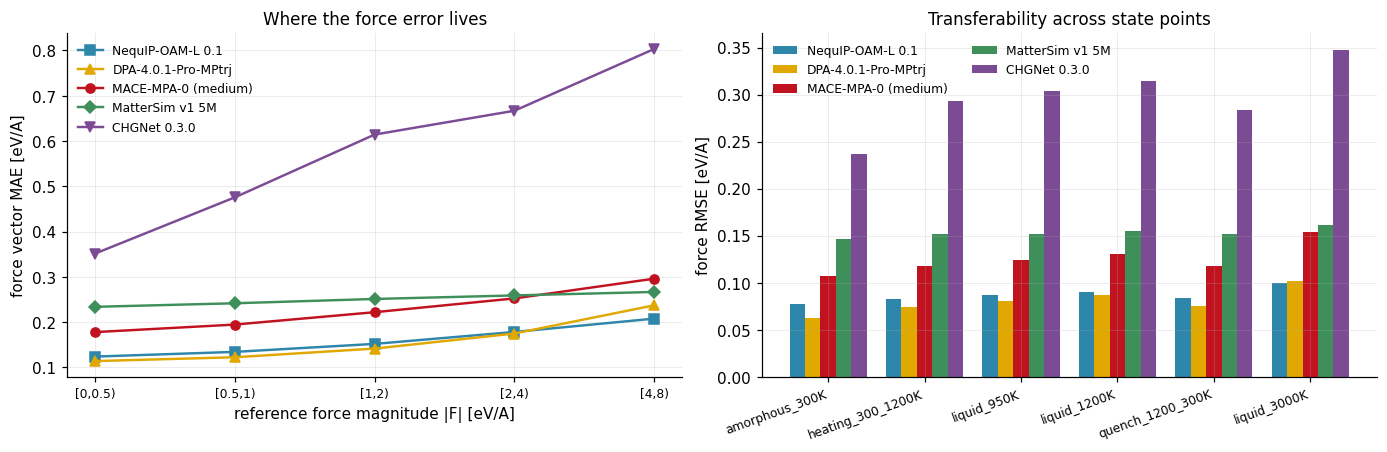

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))

# --- error vs force magnitude ---------------------------------------------
ax = axes[0]
bins_df = cm.metric_table(ORDER, r"^L0\.force_vector_mae\.", ("L0_audit",))
bin_order = ["|F|=[0,0.5)", "|F|=[0.5,1)", "|F|=[1,2)", "|F|=[2,4)", "|F|=[4,8)"]
for k in ORDER:
    sub = bins_df[bins_df["model"] == k].set_index("metric_id")
    v = [sub.loc[f"L0.force_vector_mae.{b}", "value"]
         if f"L0.force_vector_mae.{b}" in sub.index else np.nan for b in bin_order]
    ax.plot(range(len(bin_order)), v, marker=cm.marker(k), color=cm.color(k), label=LABELS[k])
ax.set_xticks(range(len(bin_order)))
ax.set_xticklabels([b.replace("|F|=", "") for b in bin_order], fontsize=8)
ax.set_xlabel("reference force magnitude |F| [eV/A]")
ax.set_ylabel("force vector MAE [eV/A]")
ax.set_title("Where the force error lives")
ax.legend(fontsize=8)

# --- transferability across the state points the frames were drawn from ----
ax = axes[1]
stage_df = cm.metric_table(ORDER, r"^L0\.force_rmse\.state_kind=", ("L0_audit",))
STAGE_ORDER = ["amorphous_300K", "heating_300_1200K", "liquid_950K", "liquid_1200K",
               "quench_1200_300K", "liquid_3000K"]
stages = [s for s in STAGE_ORDER if any(stage_df["metric_id"].str.endswith("=" + s))]
x = np.arange(len(stages))
w = 0.16
for i, k in enumerate(ORDER):
    sub = stage_df[stage_df["model"] == k].set_index("metric_id")
    v = [sub.loc[f"L0.force_rmse.state_kind={s}", "value"] for s in stages]
    ax.bar(x + (i - 2) * w, v, width=w, color=cm.color(k), label=LABELS[k])
ax.set_xticks(x)
ax.set_xticklabels(stages, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("force RMSE [eV/A]")
ax.set_title("Transferability across state points")
ax.legend(fontsize=8, ncol=2)
plt.show()

## 4. L1 — PES 健全性与轨迹稳定性（无参考，S/A 级证据）

这一级是 L2–L5 的门控：23 项病理筛查，任意一项失败即整体不通过。**五个模型里三个通过**
（MACE、NequIP、MatterSim），DPA-4 和 CHGNet 关在同一处：二体势能曲线的短程排斥壁。

后 17 项（对称性与解析导数、晶格扫描、2000 K 探针、时间步敏感性、NVE 守恒）**五个模型全过**，
所有失败都集中在那 6 条二体曲线上。

下图把六条曲线全画出来，灰底是判据区 **r ≤ 1.6 Å**——能量在这里必须单调上升。
DPA-4 和 CHGNet 六条全部在这个区间掉头向下，这是 MPtrj 训练集里没有近距离接触的直接后果：
模型从没见过原子挤在一起的构型，也就没学到排斥。CHGNet 尤其能看出机制：六条曲线在 1.0 Å
全部收敛到 ~22.5 eV，**跟是什么元素无关**——网络输出撞到天花板，壁不再上升。

> 这一级的判据本身在本轮修正过一次。h² 收敛比原来对全网格取 max，而细网格上残差最大处
> 往往是 r=1.02 Å——中心差分能存在的第一个格点，它跨过 r_min 本身（壁最陡处、采样区间边缘），
> 且这个点在 h 加倍时会外移。于是比值拿边缘主导的分子除内部主导的分母，测的不再是收敛阶：
> NequIP 的 Te–Te 被报成 2.4985（内部值 3.84），MACE 的 Ge–Ge 报成 2.88（内部 3.92）。
> 现在比值只在 `convergence_window_A`（两端各裁 3 个粗网格步，此处 1.12–7.88 Å）上测；
> `max_force_mismatch` 仍在全网格上测。修正后 NequIP 与 MatterSim 从「关」变为「通过」，
> DPA-4 与 CHGNet 不受影响——它们栽在单调排斥这个纯符号检验上。

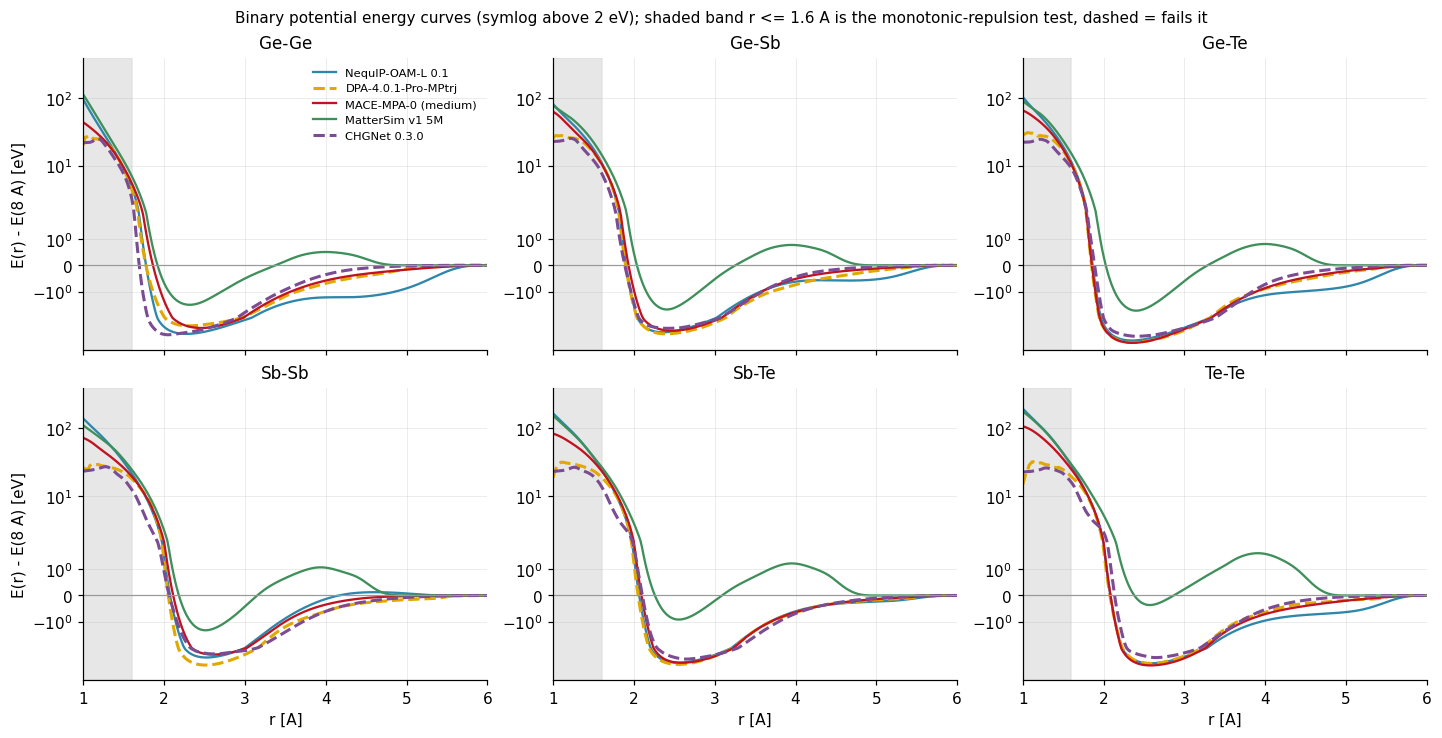

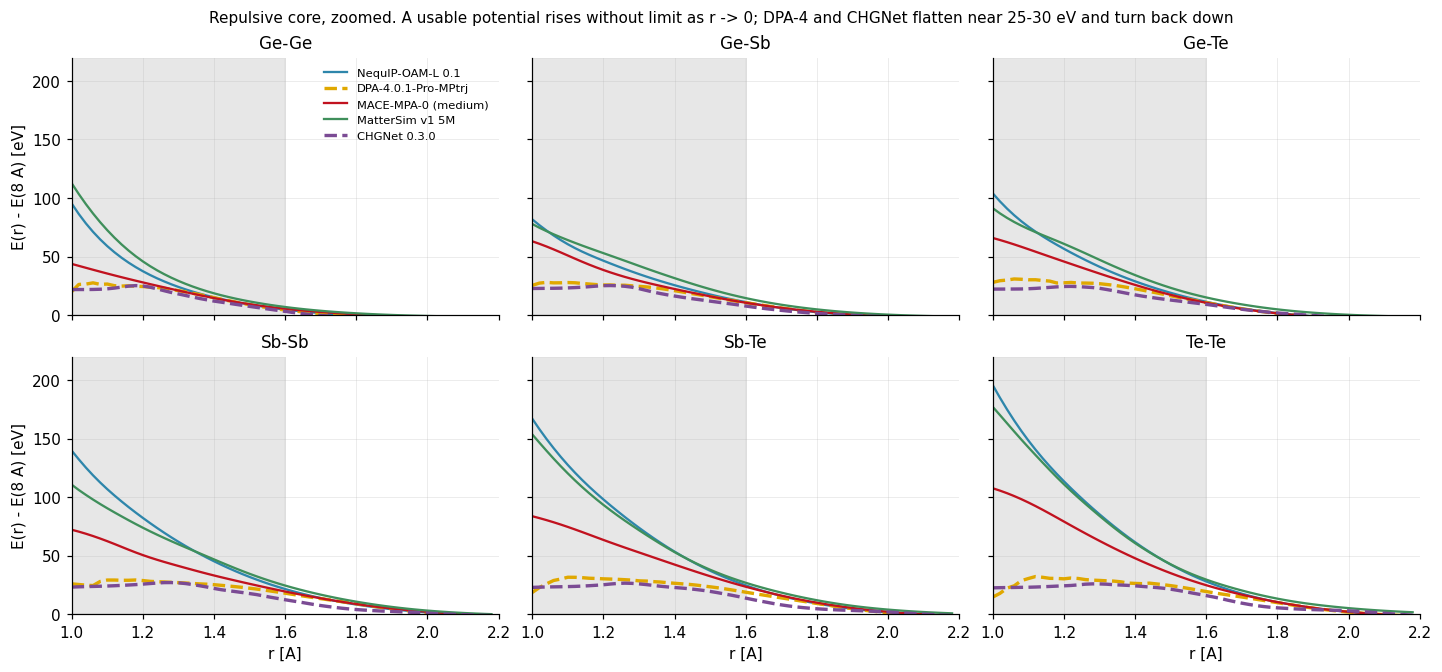

,model,repulsive walls ok,max dF/dE mismatch,min h^2 convergence
0,NequIP-OAM-L 0.1,6/6,0.00264,3.53
1,DPA-4.0.1-Pro-MPtrj,0/6,1.01,0.59
2,MACE-MPA-0 (medium),6/6,0.00551,3.69
3,MatterSim v1 5M,6/6,0.00792,2.64
4,CHGNet 0.3.0,0/6,0.165,0.62


In [7]:
PAIRS = ["Ge-Ge", "Ge-Sb", "Ge-Te", "Sb-Sb", "Sb-Te", "Te-Te"]
pecs = {k: cm.pec_curves(k) for k in ORDER}

fig, axes = plt.subplots(2, 3, figsize=(13, 6.6), sharex=True)
for ax, pair in zip(axes.ravel(), PAIRS):
    ax.axvspan(1.0, 1.6, color="#dddddd", alpha=0.7, zorder=0)
    for k in ORDER:
        curves = pecs.get(k)
        if not curves or pair not in curves:
            continue
        c = curves[pair]
        ok = c["monotonic_repulsive"]
        ax.plot(c["r"], c["energy"], color=cm.color(k), lw=1.5 if ok else 2.0,
                ls="-" if ok else "--", label=LABELS[k])
    ax.axhline(0.0, color="#999999", lw=0.8)
    ax.set_xlim(1.0, 6.0)
    # symlog: a linear window deep enough to show the -5 eV well cannot also
    # show the 200 eV wall, and the wall is exactly where the test fails
    ax.set_yscale("symlog", linthresh=2.0, linscale=0.7)
    ax.set_ylim(-6, 400)
    ax.set_title(pair)
    if ax in axes[1]:
        ax.set_xlabel("r [A]")
    if ax in axes[:, 0]:
        ax.set_ylabel("E(r) - E(8 A) [eV]")
axes[0, 0].legend(fontsize=7.5)
fig.suptitle("Binary potential energy curves (symlog above 2 eV); shaded band "
             "r <= 1.6 A is the monotonic-repulsion test, dashed = fails it",
             fontsize=10)
plt.show()

# --- the core, zoomed: this is where the two closed gates actually close ---
fig, axes = plt.subplots(2, 3, figsize=(13, 6.0), sharex=True, sharey=True)
for ax, pair in zip(axes.ravel(), PAIRS):
    ax.axvspan(1.0, 1.6, color="#dddddd", alpha=0.7, zorder=0)
    for k in ORDER:
        curves = pecs.get(k)
        if not curves or pair not in curves:
            continue
        c = curves[pair]
        m = c["r"] <= 2.2
        ok = c["monotonic_repulsive"]
        ax.plot(c["r"][m], c["energy"][m], color=cm.color(k), lw=1.5 if ok else 2.2,
                ls="-" if ok else "--", label=LABELS[k])
    ax.set_xlim(1.0, 2.2)
    ax.set_ylim(0, 220)
    ax.set_title(pair)
    if ax in axes[1]:
        ax.set_xlabel("r [A]")
    if ax in axes[:, 0]:
        ax.set_ylabel("E(r) - E(8 A) [eV]")
axes[0, 0].legend(fontsize=7.5, loc="upper right")
fig.suptitle("Repulsive core, zoomed. A usable potential rises without limit as r -> 0; "
             "DPA-4 and CHGNet flatten near 25-30 eV and turn back down", fontsize=10)
plt.show()

summary = pd.DataFrame([
    {"model": LABELS[k],
     "repulsive walls ok": f"{sum(c['monotonic_repulsive'] for c in pecs[k].values())}/6",
     "max dF/dE mismatch": f"{max(c['max_force_mismatch'] for c in pecs[k].values()):.3g}",
     "min h^2 convergence": f"{min(c['convergence_ratio'] for c in pecs[k].values()):.2f}"}
    for k in ORDER if pecs.get(k)
])
display(summary)

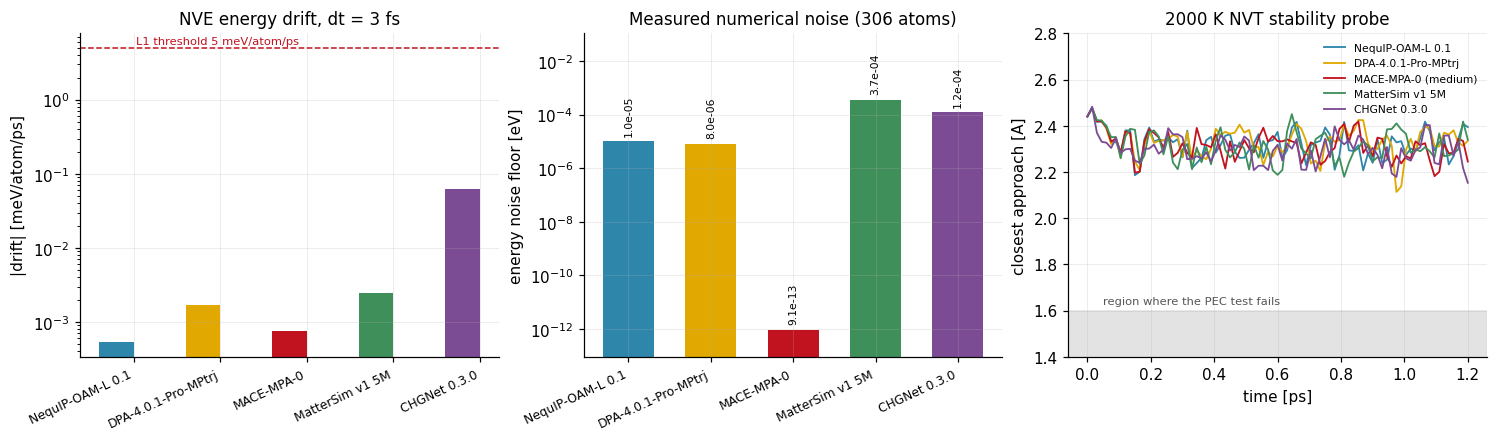

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))

# --- NVE drift vs the AIMD preflight ---------------------------------------
ax = axes[0]
drift = cm.metric_table(ORDER, r"^L1\.nve_drift\.dt=3fs$", ("L1",)).set_index("model")
noise = {}
for k in ORDER:
    res = json.loads(next((paths.MODEL_RESULTS_ROOT / k).glob("L1_*.json")).read_text())
    noise[k] = res["context"].get("measured_energy_noise_eV", np.nan)
x = np.arange(len(ORDER))
ax.bar(x - 0.2, [abs(drift.loc[k, "value"]) for k in ORDER], width=0.4,
       color=[cm.color(k) for k in ORDER], label="|NVE drift|")
ax.axhline(5.0, color="#c1121f", ls="--", lw=1.0)
ax.text(0.02, 5.6, "L1 threshold 5 meV/atom/ps", fontsize=7.5, color="#c1121f")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels([LABELS[k].split(" (")[0] for k in ORDER], rotation=25, ha="right", fontsize=8)
ax.set_ylabel("|drift| [meV/atom/ps]")
ax.set_title("NVE energy drift, dt = 3 fs")

# --- measured numerical noise floor ----------------------------------------
ax = axes[1]
ax.bar(x, [noise[k] for k in ORDER], color=[cm.color(k) for k in ORDER], width=0.62)
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels([LABELS[k].split(" (")[0] for k in ORDER], rotation=25, ha="right", fontsize=8)
ax.set_ylabel("energy noise floor [eV]")
ax.set_title("Measured numerical noise (306 atoms)")
lo = min(noise.values()); hi = max(noise.values())
ax.set_ylim(lo / 10, hi * 300)          # headroom for the rotated labels
for xi, k in zip(x, ORDER):
    ax.text(xi, noise[k] * 1.6, f"{noise[k]:.1e}", ha="center", va="bottom",
            fontsize=7, rotation=90)

# --- closest approach during the 2000 K probe ------------------------------
ax = axes[2]
for k in ORDER:
    z = cm.load_npz(k, "l1_stability_2000K.npz")
    if z is None:
        continue
    ax.plot(z["time_fs"] / 1000.0, z["min_distance"], color=cm.color(k), lw=1.2, label=LABELS[k])
ax.axhspan(1.0, 1.6, color="#dddddd", alpha=0.8, zorder=0)
ax.text(0.05, 1.63, "region where the PEC test fails", fontsize=7.5, color="#555555")
ax.set_ylim(1.4, 2.8)
ax.set_xlabel("time [ps]")
ax.set_ylabel("closest approach [A]")
ax.set_title("2000 K NVT stability probe")
ax.legend(fontsize=7, loc="upper right")
plt.show()

右图是这一级最重要的读法：**被判失败的 r ≤ 1.6 Å 区间，五个模型在 2000 K 探针里都没有真正走到**
（最近接触都在 2.1 Å 以上）。所以 DPA-4 与 CHGNet 的门控关闭说明的是「还能往多极端推」的上界
——高温、高压、级联碰撞——而不是说它们在本项目的熔淬–非晶流程里不能用；DPA-4 的 L4 满分就是证据。

中图解释了框架为此做的一处修正：float32 模型（MatterSim、CHGNet）在 306 原子胞上的
能量噪声地板约 10⁻⁴ eV，比 float64 模型高 8 个量级。原来 1 µeV 的平移不变性阈值是给
float64 写的，会把这个舍入判成对称性破缺；现在容差按**实测**噪声定标
（`l1_pes.energy_noise()`，用刚体平移 + 原子序号置换两种严格不变的变换）。

## 5. L2 — 有序相的静态平衡性质

对照的是 phase-1 已完成的 DFT 任务（B 级证据）：四个晶体参考的弛豫几何 + 六方相 7 点 EOS。

**四级相序阶梯**（DFT，相对最低相 mp-1224375）：mp-3534 (P-3m1) +15.13、
mp-1224407 (Cm) +37.81、cubic +54.65 meV/atom。两个 P-3m1 是三角相的两种堆垛序列，
它们之间那 15.13 meV/atom 是阶梯里分辨力最强的一格。

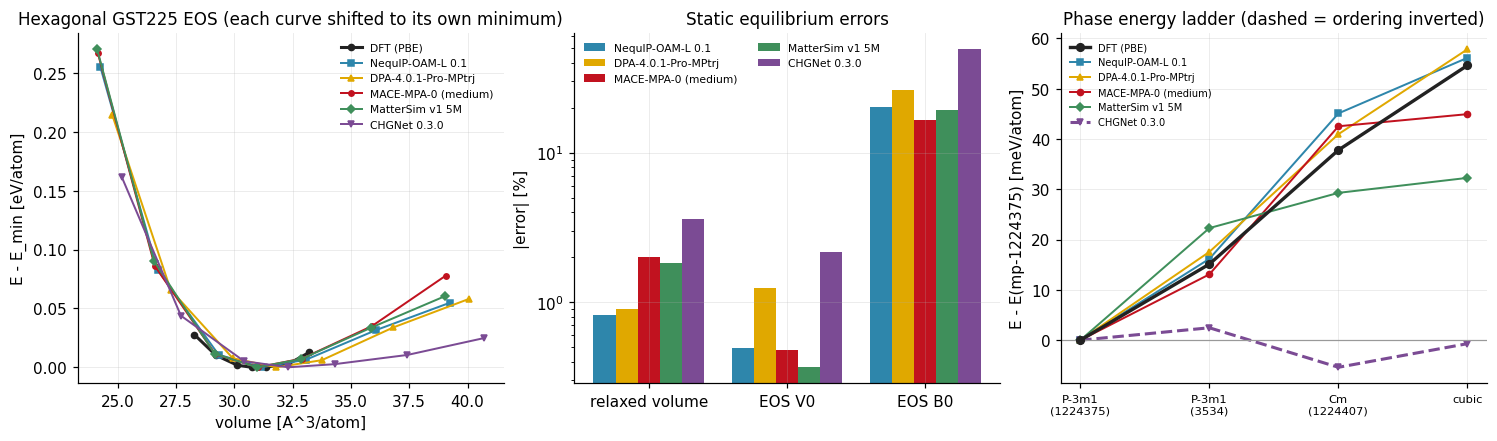

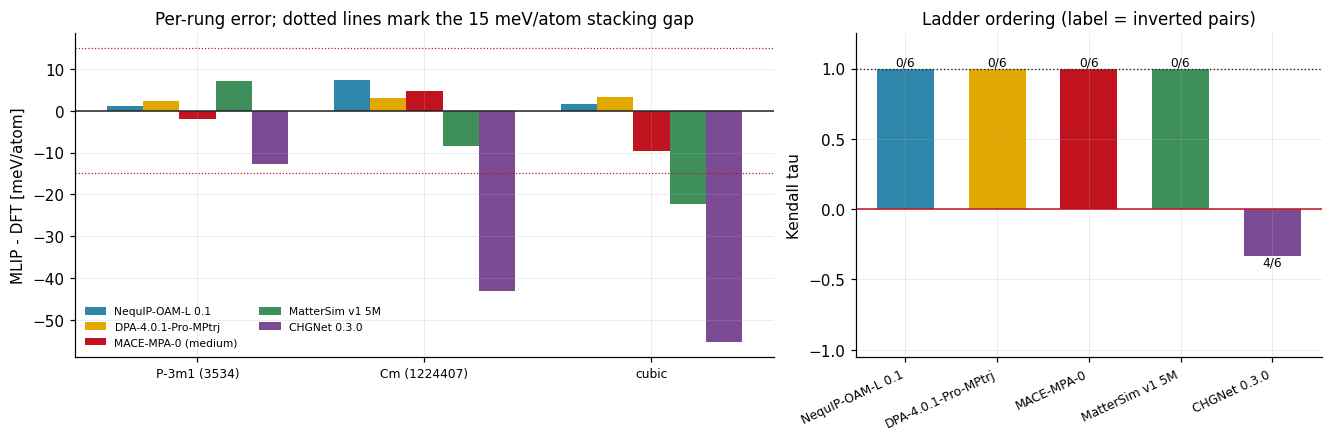

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))

# --- hexagonal EOS ---------------------------------------------------------
ax = axes[0]
dft = cm.load_npz(ORDER[0], "l2_eos_hex_dft.npz")
if dft is not None:
    v = dft["volumes"] / float(dft["n_atoms"])
    e = dft["energies"] / float(dft["n_atoms"])
    ax.plot(v, e - e.min(), color=cm.REFERENCE_COLOR, marker="o", ms=4, lw=2.0, label="DFT (PBE)")
for k in ORDER:
    z = cm.load_npz(k, "l2_eos_hex_mlip.npz")
    if z is None:
        continue
    v = z["volumes"] / float(z["n_atoms"])
    e = z["energies"] / float(z["n_atoms"])
    ax.plot(v, e - e.min(), color=cm.color(k), marker=cm.marker(k), ms=3.5, lw=1.3, label=LABELS[k])
ax.set_xlabel("volume [A^3/atom]")
ax.set_ylabel("E - E_min [eV/atom]")
ax.set_title("Hexagonal GST225 EOS (each curve shifted to its own minimum)")
ax.legend(fontsize=7, loc="upper right")

# --- relaxation and EOS errors --------------------------------------------
ax = axes[1]
groups = [("relaxed volume", r"^L2\.relax\..*\.volume_error$"),
          ("EOS V0", r"^L2\.eos\..*\.V0_error$"),
          ("EOS B0", r"^L2\.eos\..*\.B0_error$")]
x = np.arange(len(groups))
w = 0.16
for i, k in enumerate(ORDER):
    v = []
    for _, pat in groups:
        df = cm.metric_table([k], pat, ("L2",))
        v.append(float(np.mean(np.abs(df["value"].dropna()))) if len(df) else np.nan)
    ax.bar(x + (i - 2) * w, v, width=w, color=cm.color(k), label=LABELS[k])
ax.set_xticks(x)
ax.set_xticklabels([g[0] for g in groups])
ax.set_yscale("log")
ax.set_ylabel("|error| [%]")
ax.set_title("Static equilibrium errors")
ax.legend(fontsize=7, ncol=2)

# --- the phase ladder, not just its two ends ------------------------------
# The old panel here was the single cubic-minus-hexagonal sign test.  That test
# compares every phase against one base, so with the DFT-lowest phase as base it
# is satisfied by construction for all of them -- it only ever tested one pair.
ax = axes[2]
PHASE_LABEL = {"mp1224375": "P-3m1\n(1224375)", "mp3534": "P-3m1\n(3534)",
               "mp1224407": "Cm\n(1224407)", "cubic": "cubic"}
# metric_record, not metric_table: a ladder is not a scalar, and both energy
# ladders live in the metric's `extra`
ladders = {}
for k in ORDER:
    rec = cm.metric_record(k, "L2.phase_ladder.inversions", ("L2",))
    if rec is not None:
        ladders[k] = rec

if ladders:
    ref = next(iter(ladders.values()))["extra"]["dft_ladder_meV_per_atom"]
    keys = sorted(ref, key=lambda q: ref[q])
    xs = np.arange(len(keys))
    ax.plot(xs, [ref[q] for q in keys], color=cm.REFERENCE_COLOR, marker="o", ms=5,
            lw=2.2, label="DFT (PBE)", zorder=5)
    for k, rec in ladders.items():
        m = rec["extra"]["model_ladder_meV_per_atom"]
        bad = int(rec["value"]) > 0
        ax.plot(xs, [m[q] for q in keys], color=cm.color(k), marker=cm.marker(k),
                ms=4, lw=2.0 if bad else 1.3, ls="--" if bad else "-", label=LABELS[k])
    ax.axhline(0.0, color="#999999", lw=0.8)
    ax.set_xticks(xs)
    ax.set_xticklabels([PHASE_LABEL[q] for q in keys], fontsize=7.5)
    ax.set_ylabel("E - E(mp-1224375) [meV/atom]")
    ax.set_title("Phase energy ladder (dashed = ordering inverted)")
    ax.legend(fontsize=6.5, loc="upper left")
plt.show()

# per-rung error, and how scrambled the ladder is
fig, axes = plt.subplots(1, 2, figsize=(12.0, 3.9), width_ratios=[1.5, 1])
ax = axes[0]
rungs = [q for q in keys if q != "mp1224375"] if ladders else []
x = np.arange(len(rungs)); w = 0.16
for i, k in enumerate(ORDER):
    rec = ladders.get(k)
    if rec is None:
        continue
    m = rec["extra"]["model_ladder_meV_per_atom"]
    d = rec["extra"]["dft_ladder_meV_per_atom"]
    ax.bar(x + (i - 2) * w, [m[q] - d[q] for q in rungs], width=w,
           color=cm.color(k), label=LABELS[k])
ax.axhline(0.0, color="#222222", lw=1.0)
for y in (-15, 15):
    ax.axhline(y, color="#c1121f", lw=0.8, ls=":")
ax.set_xticks(x); ax.set_xticklabels([PHASE_LABEL[q].replace("\n", " ") for q in rungs], fontsize=8)
ax.set_ylabel("MLIP - DFT [meV/atom]")
ax.set_title("Per-rung error; dotted lines mark the 15 meV/atom stacking gap")
ax.legend(fontsize=7, ncol=2)

ax = axes[1]
tau = cm.metric_table(ORDER, r"^L2\.phase_ladder\.kendall_tau$", ("L2",)).set_index("model")
inv = cm.metric_table(ORDER, r"^L2\.phase_ladder\.inversions$", ("L2",)).set_index("model")
have = [k for k in ORDER if k in tau.index]
ax.bar(np.arange(len(have)), [tau.loc[k, "value"] for k in have],
       color=[cm.color(k) for k in have], width=0.62)
ax.axhline(1.0, color="#222222", lw=0.9, ls=":")
ax.axhline(0.0, color="#c1121f", lw=1.0)
for xi, k in enumerate(have):
    n = int(inv.loc[k, "value"])
    ax.text(xi, tau.loc[k, "value"], f"{n}/6" if n else "0/6",
            ha="center", va="bottom" if tau.loc[k, "value"] > 0 else "top", fontsize=8)
ax.set_xticks(np.arange(len(have)))
ax.set_xticklabels([LABELS[k].split(" (")[0] for k in have], rotation=25, ha="right", fontsize=8)
ax.set_ylim(-1.05, 1.25)
ax.set_ylabel("Kendall tau")
ax.set_title("Ladder ordering (label = inverted pairs)")
plt.show()

右上第三张图是这一级最关键的读法：**四条阶梯叠在 DFT 那条黑线上**。四个模型把六对顺序
全排对（Kendall τ = 1），CHGNet 0.3.0 判反四对、τ = −0.333——比随机还差。它的四个相
全部落在 8 meV/atom 之内（−0.7、+2.5、−5.4），整条阶梯被压平并局部倒置，
这是定性错误而不是精度问题。

逐级误差图里 ±15 meV/atom 那两条虚线是两个 P-3m1 堆垛之间的真实间距，用作误差量级的尺子：

| 模型 | 顺序 | Kendall τ | 堆垛格误差 | 最差一级 |
|---|---|---|---|---|
| NequIP-OAM-L | 6/6 对 | +1.000 | **+1.05** | +7.29 (Cm) |
| DPA-4.0.1-Pro | 6/6 对 | +1.000 | +2.43 | +3.21 (cubic) |
| MACE-MPA-0 | 6/6 对 | +1.000 | −2.03 | −9.70 (cubic) |
| MatterSim 5M | 6/6 对 | +1.000 | +7.16 | −22.37 (cubic) |
| CHGNet 0.3.0 | **判反 4 对** | **−0.333** | −12.66 | −55.34 (cubic) |

MatterSim 值得单独看一句：它 0 逆序，但整条阶梯被压缩到 32 meV/atom（DFT 是 54.7），
cubic 与 Cm 之间只剩 3 meV/atom 的间距（DFT 16.8）——顺序是勉强保住的，
逐级误差指标才抓得到这一点。这正是二元符号检验看不见的东西。

### 组成修正后的形成能

相序阶梯比较的是同组成的相对能量；**形成能** $\Delta H_f = E/N - \sum_X x_X\,\mu_X$ 还要求模型把
三种单质的能量也放对。两侧各用自己的单质参考（DFT 用 `L2_{ge,sb,te}_static`，模型用自己弛豫的单质胞），
所以协议间的逐元素常数偏移相互抵消，剩下的是模型对"化合 vs 单质"能量差的误差。
修正后的 cubic−hex 能量差是同一件事的另一面：两相都参照单质基态，再看顺序是否保住。

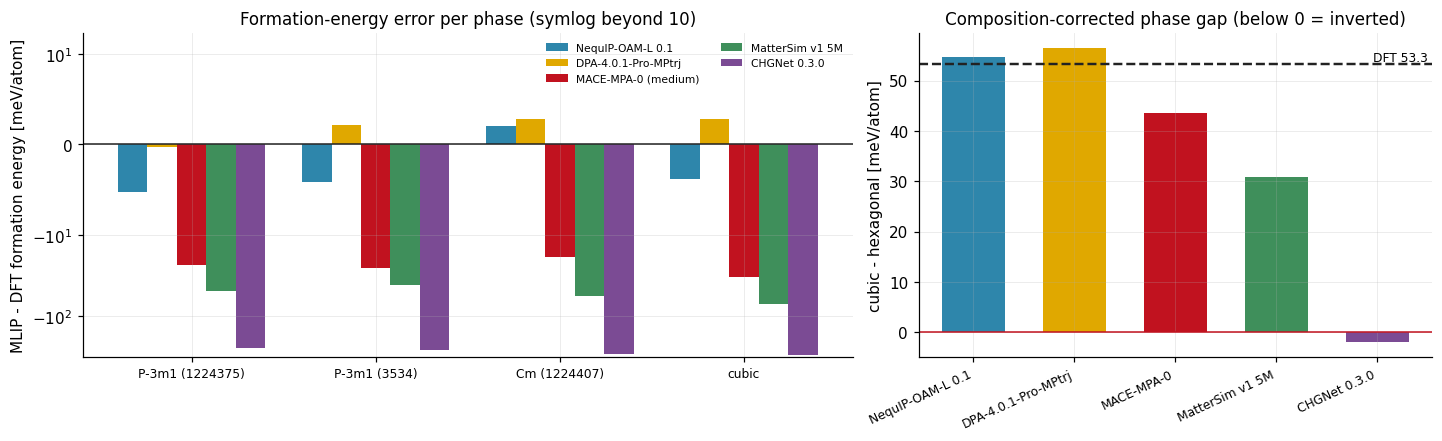

,mu_Ge error (meV/atom),mu_Sb error (meV/atom),mu_Te error (meV/atom),gap (meV/atom),ordering kept
model,,,,,
NequIP-OAM-L 0.1,-119.79,16.12,12.71,54.74,True
DPA-4.0.1-Pro-MPtrj,-105.67,4.20,6.83,56.45,True
MACE-MPA-0 (medium),-116.53,26.74,47.99,43.50,True
MatterSim v1 5M,-29.53,42.05,72.72,30.86,True
CHGNet 0.3.0,37.06,75.78,-23.56,-1.94,False


注：mu 的绝对差包含协议间的元素常数偏移（PBE vs 模型训练集的参考态），本身不计分；
    计分的是两侧各自参照单质之后的形成能差。


In [10]:
PHASES = ["mp1224375", "mp3534", "mp1224407", "cubic"]
fe = cm.metric_table(ORDER, r"^L2\.formation_energy\.dE_error\.", ("L2",))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), width_ratios=[1.5, 1])
ax = axes[0]
x = np.arange(len(PHASES)); w = 0.16
for i, k in enumerate(ORDER):
    sub = fe[fe["model"] == k].set_index("metric_id")
    v = [sub.loc[f"L2.formation_energy.dE_error.{p}", "value"]
         if f"L2.formation_energy.dE_error.{p}" in sub.index else np.nan for p in PHASES]
    ax.bar(x + (i - 2) * w, v, width=w, color=cm.color(k), label=LABELS[k])
ax.axhline(0, color="#222", lw=1.0)
ax.set_xticks(x); ax.set_xticklabels([PHASE_LABEL[p].replace("\n", " ") for p in PHASES], fontsize=8)
ax.set_yscale("symlog", linthresh=10.0)
ax.set_ylabel("MLIP - DFT formation energy [meV/atom]")
ax.set_title("Formation-energy error per phase (symlog beyond 10)")
ax.legend(fontsize=7, ncol=2)

ax = axes[1]
gap = {k: cm.metric_record(k, "L2.formation_energy.cubic_minus_hexagonal", ("L2",)) for k in ORDER}
dft_gap = next(r["extra"]["dft_meV_per_atom"] for r in gap.values() if r is not None)
have = [k for k in ORDER if gap[k] is not None]
ax.bar(np.arange(len(have)), [gap[k]["value"] for k in have], color=[cm.color(k) for k in have], width=0.62)
ax.axhline(dft_gap, color=cm.REFERENCE_COLOR, lw=1.6, ls="--")
ax.text(len(have) - 0.5, dft_gap, f"DFT {dft_gap:.1f}", ha="right", va="bottom", fontsize=8)
ax.axhline(0, color="#c1121f", lw=1.0)
ax.set_xticks(np.arange(len(have)))
ax.set_xticklabels([LABELS[k].split(" (")[0] for k in have], rotation=25, ha="right", fontsize=8)
ax.set_ylabel("cubic - hexagonal [meV/atom]")
ax.set_title("Composition-corrected phase gap (below 0 = inverted)")
plt.show()

display(pd.DataFrame([{
    "model": LABELS[k],
    **{f"mu_{el} error (meV/atom)": 1000 * (gap[k]["extra"]["mu_model_eV_per_atom"][el]
                                            - gap[k]["extra"]["mu_dft_eV_per_atom"][el])
       for el in ("Ge", "Sb", "Te")},
    "gap (meV/atom)": gap[k]["value"], "ordering kept": gap[k]["extra"]["ordering_reproduced"],
} for k in have]).set_index("model").round(2))
print("注：mu 的绝对差包含协议间的元素常数偏移（PBE vs 模型训练集的参考态），本身不计分；")
print("    计分的是两侧各自参照单质之后的形成能差。")

（形成能的读法在执行后填写。）

## 6. L3 — 无序结构（四个 canonical 状态点）

键截断、bin 宽、环算法都从 AIMD 参考一次性冻结，再原样喂给五个模型的轨迹
（框架规则 5）。所以下面每一张图里，参考曲线对五个模型是同一条。
图里画的是 300 K 非晶（副本 1 ↔ 种子 0）；四个状态点、三对配对的正式判级见第 9 节。

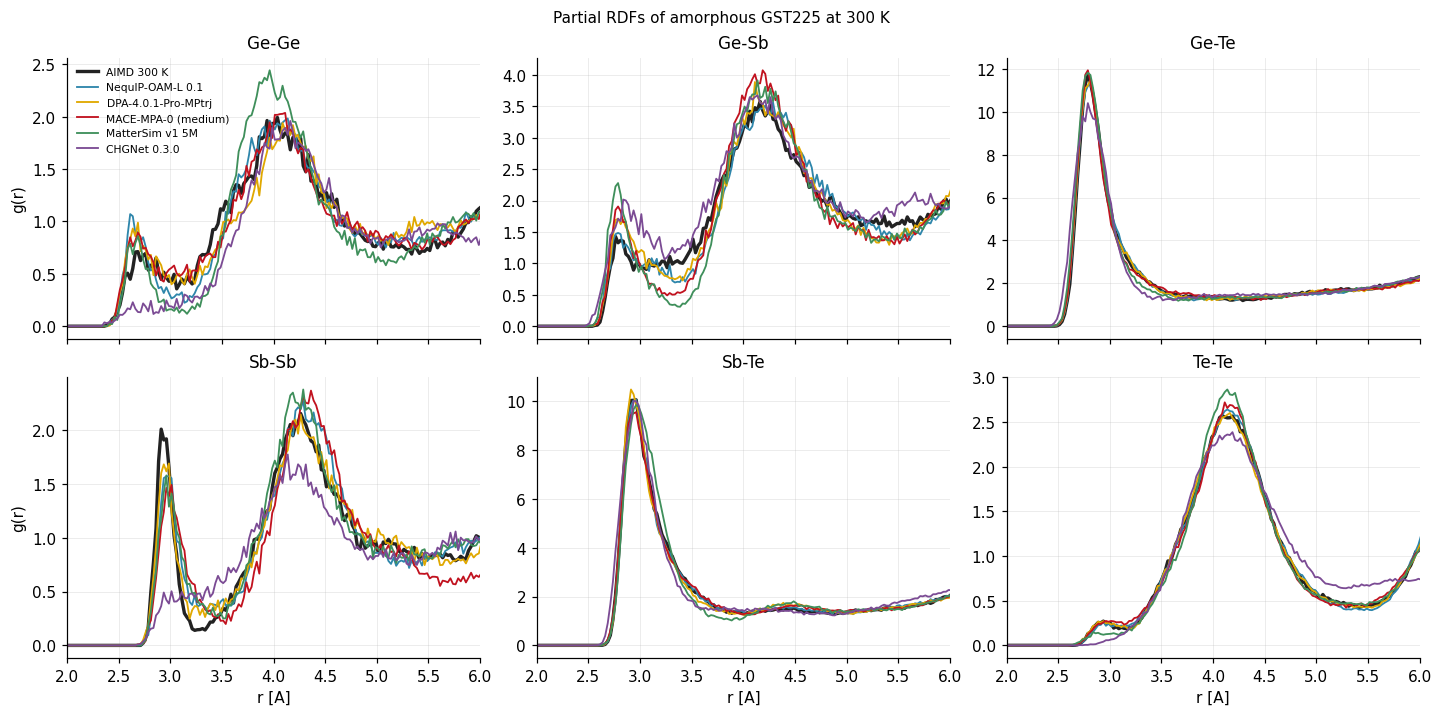

In [11]:
STATE = "canon_amorphous_300K"
l3 = {k: cm.load_npz(k, f"l3_{STATE}.npz") for k in ORDER}
ref = next(z for z in l3.values() if z is not None)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True)
for ax, pair in zip(axes.ravel(), PAIRS):
    ax.plot(ref["r"], ref[f"rdf_ref_{pair}"], color=cm.REFERENCE_COLOR, lw=2.2, label="AIMD 300 K")
    for k in ORDER:
        z = l3.get(k)
        if z is None:
            continue
        ax.plot(z["r"], z[f"rdf_model_{pair}"], color=cm.color(k), lw=1.2, label=LABELS[k])
    ax.set_xlim(2.0, 6.0)
    ax.set_title(pair)
    if ax in axes[1]:
        ax.set_xlabel("r [A]")
    if ax in axes[:, 0]:
        ax.set_ylabel("g(r)")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Partial RDFs of amorphous GST225 at 300 K", fontsize=10)
plt.show()

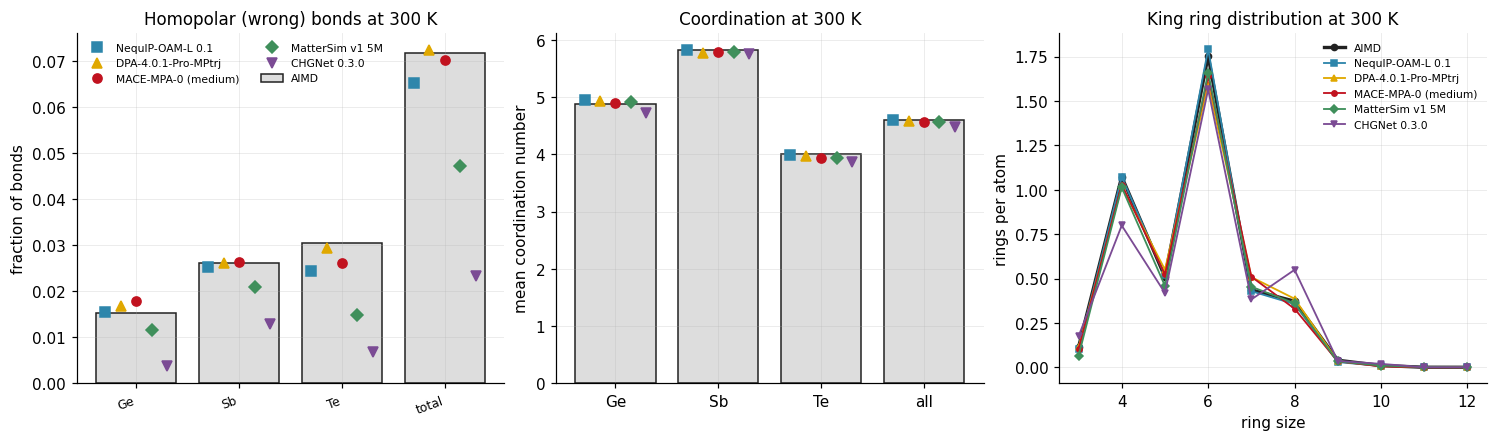

,homopolar Ge,homopolar Sb,homopolar Te,homopolar total,homopolar total / AIMD
model,,,,,
NequIP-OAM-L 0.1,0.0156,0.0253,0.0245,0.0654,0.9105
DPA-4.0.1-Pro-MPtrj,0.0169,0.0262,0.0293,0.0725,1.0092
MACE-MPA-0 (medium),0.0178,0.0263,0.0262,0.0704,0.9795
MatterSim v1 5M,0.0115,0.0208,0.0149,0.0473,0.6582
CHGNet 0.3.0,0.0037,0.0129,0.0067,0.0233,0.3249


In [12]:
def l3a_records(k, state=STATE):
    path = paths.MODEL_RESULTS_ROOT / k / f"L3a_{state}__lammps.json"
    return {r["metric_id"]: r for r in json.loads(path.read_text())["results"]}

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))

# --- homopolar bonds: the chemical-order signature -------------------------
ax = axes[0]
by_id = l3a_records(ORDER[0])
keys = sorted({m.split("L3a.homopolar.")[1].split("@")[0] for m in by_id if m.startswith("L3a.homopolar.")})
x = np.arange(len(keys))
w = 0.15
ref_vals = [by_id[f"L3a.homopolar.{key}@{STATE}"]["extra"]["reference"] for key in keys]
ax.bar(x, ref_vals, width=0.78, color="#dddddd", edgecolor=cm.REFERENCE_COLOR, label="AIMD")
for i, k in enumerate(ORDER):
    m = l3a_records(k)
    v = [m[f"L3a.homopolar.{key}@{STATE}"]["extra"]["model"] for key in keys]
    ax.plot(x + (i - 2) * w, v, marker=cm.marker(k), ls="none", ms=6,
            color=cm.color(k), label=LABELS[k])
ax.set_xticks(x)
ax.set_xticklabels(keys, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("fraction of bonds")
ax.set_title("Homopolar (wrong) bonds at 300 K")
ax.legend(fontsize=7, ncol=2)

# --- coordination numbers --------------------------------------------------
ax = axes[1]
species = ["Ge", "Sb", "Te", "all"]
x = np.arange(len(species))
ref_cn = [by_id[f"L3a.cn.{s}.mean@{STATE}"]["extra"]["reference"] for s in species]
ax.bar(x, ref_cn, width=0.78, color="#dddddd", edgecolor=cm.REFERENCE_COLOR, label="AIMD")
for i, k in enumerate(ORDER):
    m = l3a_records(k)
    ax.plot(x + (i - 2) * w, [m[f"L3a.cn.{s}.mean@{STATE}"]["extra"]["model"] for s in species],
            marker=cm.marker(k), ls="none", ms=6, color=cm.color(k), label=LABELS[k])
ax.set_xticks(x)
ax.set_xticklabels(species)
ax.set_ylabel("mean coordination number")
ax.set_title("Coordination at 300 K")

# --- ring statistics -------------------------------------------------------
ax = axes[2]
ax.plot(ref["ring_sizes"], ref["rings_ref"], color=cm.REFERENCE_COLOR, lw=2.2,
        marker="o", ms=4, label="AIMD")
for k in ORDER:
    z = l3.get(k)
    if z is None:
        continue
    ax.plot(z["ring_sizes"], z["rings_model"], color=cm.color(k),
            marker=cm.marker(k), ms=3.5, lw=1.2, label=LABELS[k])
ax.set_xlabel("ring size")
ax.set_ylabel("rings per atom")
ax.set_title("King ring distribution at 300 K")
ax.legend(fontsize=7)
plt.show()

display(pd.DataFrame([{
    "model": LABELS[k],
    **{f"homopolar {key}": l3a_records(k)[f"L3a.homopolar.{key}@{STATE}"]["extra"]["model"] for key in keys},
    "homopolar total / AIMD": l3a_records(k)[f"L3a.homopolar.total@{STATE}"]["extra"]["model"]
                              / by_id[f"L3a.homopolar.total@{STATE}"]["extra"]["reference"],
} for k in ORDER]).set_index("model").round(4))

（同极键与配位的读法在执行后填写。）

## 7. L4 — 三个液体温度的扩散

`fit_diffusion` 用 log–log 斜率判扩散区，拟合窗口钉在两侧共同的绝对时间上。
跨模型比较用 `Δlog₁₀D`，在对数空间对称；三个温度分别是 950 K、1200 K 与 3000 K。

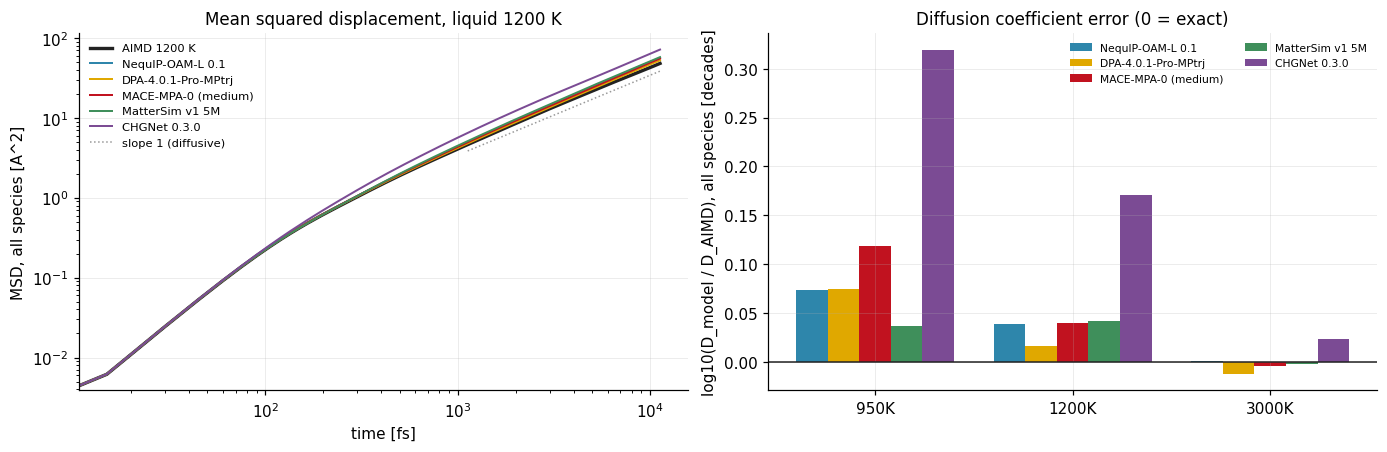

In [13]:
L4_STATES = ["canon_liquid_950K", "canon_liquid_1200K", "canon_liquid_3000K"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))

ax = axes[0]
l4ref = cm.load_npz(ORDER[0], "l4_canon_liquid_1200K.npz")
ax.loglog(l4ref["time_ref"], l4ref["msd_ref_all"], color=cm.REFERENCE_COLOR, lw=2.2, label="AIMD 1200 K")
for k in ORDER:
    z = cm.load_npz(k, "l4_canon_liquid_1200K.npz")
    if z is None:
        continue
    ax.loglog(z["time_model"], z["msd_model_all"], color=cm.color(k), lw=1.3, label=LABELS[k])
t = l4ref["time_ref"][l4ref["time_ref"] > 0]
guide = np.array([t[len(t) // 10], t[-1]])
ax.loglog(guide, guide * (l4ref["msd_ref_all"][-1] / l4ref["time_ref"][-1]) * 0.8,
          color="#999999", ls=":", lw=1.0, label="slope 1 (diffusive)")
ax.set_xlabel("time [fs]")
ax.set_ylabel("MSD, all species [A^2]")
ax.set_title("Mean squared displacement, liquid 1200 K")
ax.legend(fontsize=7.5)

ax = axes[1]
dl = cm.metric_table(ORDER, r"^L4\.diffusion\.all\.delta_log10D@", ("L4",))
x = np.arange(len(L4_STATES))
w = 0.16
for i, k in enumerate(ORDER):
    sub = dl[dl["model"] == k].set_index("metric_id")
    v = [sub.loc[f"L4.diffusion.all.delta_log10D@{s}", "value"]
         if f"L4.diffusion.all.delta_log10D@{s}" in sub.index else np.nan for s in L4_STATES]
    ax.bar(x + (i - 2) * w, v, width=w, color=cm.color(k), label=LABELS[k])
ax.axhline(0.0, color="#222222", lw=1.0)
ax.set_xticks(x)
ax.set_xticklabels([s.replace("canon_liquid_", "") for s in L4_STATES])
ax.set_ylabel("log10(D_model / D_AIMD), all species [decades]")
ax.set_title("Diffusion coefficient error (0 = exact)")
ax.legend(fontsize=7, ncol=2)
plt.show()

## 8. L5 — 淬火（1200 → 300 K，60 ps）与升温（300 → 1200 K）

灰带是参考的 3σ 容差带（参考自身窗口内涨落，附下限）。每条模型曲线是种子 0 对副本 1；
三对配对与副本对照的判级见第 9 节。

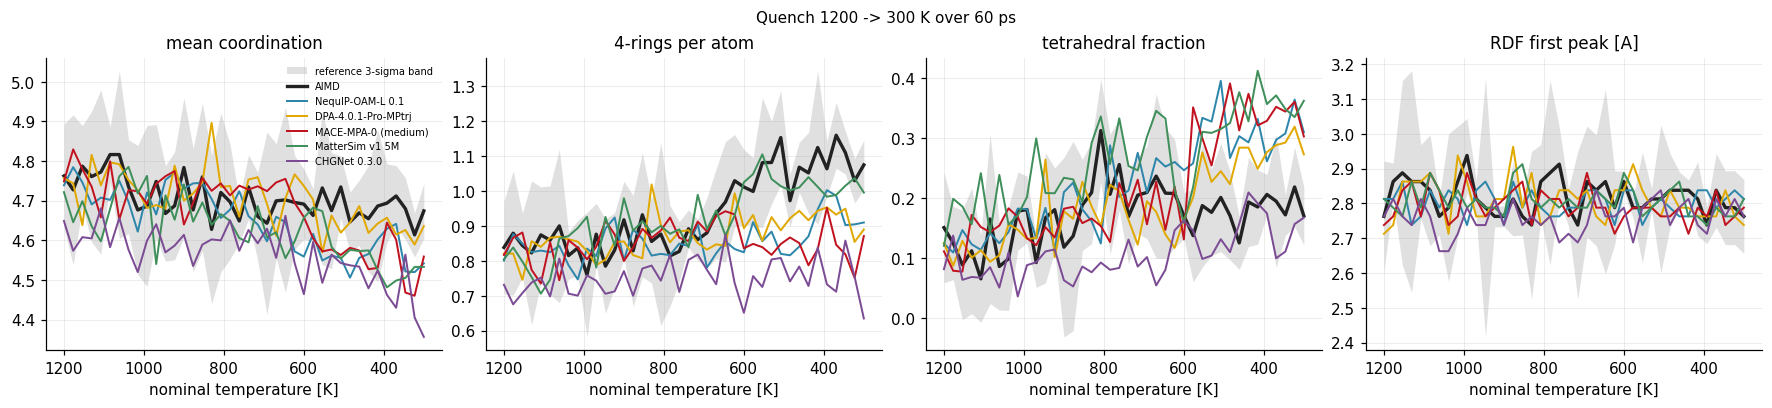

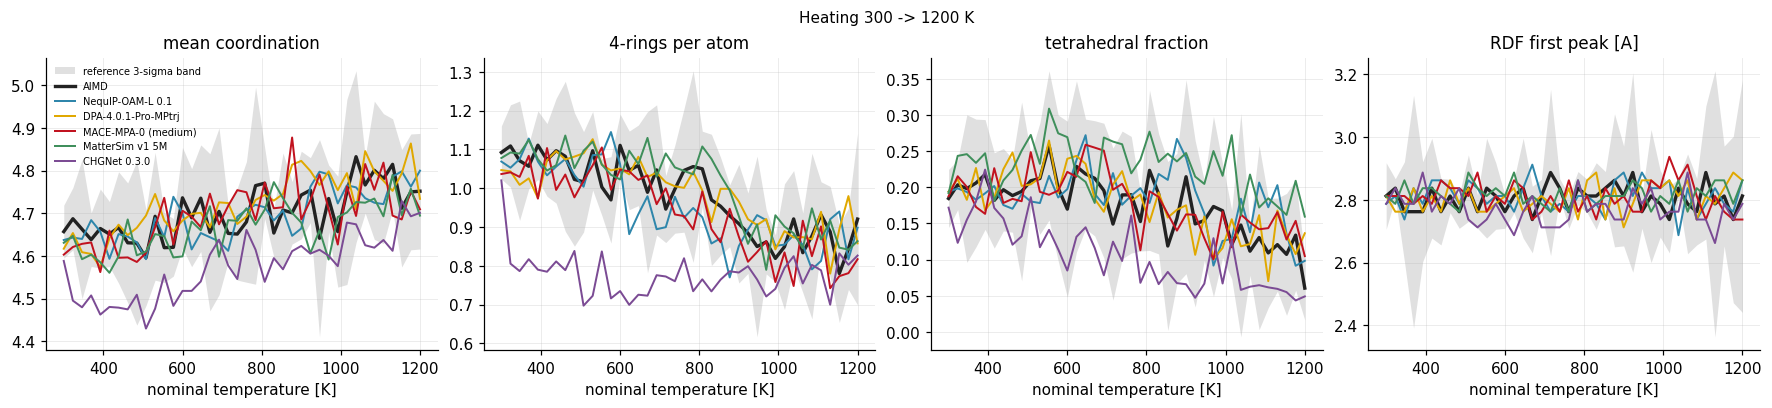

In [14]:
OBSERVABLES = [("mean_cn_all", "mean coordination"),
               ("four_rings_per_atom", "4-rings per atom"),
               ("tetrahedral_fraction", "tetrahedral fraction"),
               ("rdf_first_peak_A", "RDF first peak [A]")]

for state, title in (("canon_quench", "Quench 1200 -> 300 K over 60 ps"),
                     ("canon_heating", "Heating 300 -> 1200 K")):
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
    z0 = cm.load_npz(ORDER[0], f"l5_{state}.npz")
    for ax, (obs, label) in zip(axes, OBSERVABLES):
        x_ref = z0["ref_nominal_temperature_K"]
        ref_y, band = z0[f"ref_{obs}"], z0[f"band_{obs}"]
        ax.fill_between(x_ref, ref_y - band, ref_y + band, color="#bbbbbb", alpha=0.45, lw=0,
                        label="reference 3-sigma band")
        ax.plot(x_ref, ref_y, color=cm.REFERENCE_COLOR, lw=2.2, label="AIMD")
        for k in ORDER:
            z = cm.load_npz(k, f"l5_{state}.npz")
            if z is None:
                continue
            ax.plot(z["model_nominal_temperature_K"], z[f"model_{obs}"], color=cm.color(k), lw=1.3,
                    label=LABELS[k])
        if state == "canon_quench":
            ax.invert_xaxis()
        ax.set_xlabel("nominal temperature [K]")
        ax.set_title(label)
    axes[0].legend(fontsize=6.5)
    fig.suptitle(title, fontsize=10)
    plt.show()

## 9. 绝对判级：模型离 AIMD 不比 AIMD 离自己更远，就是 A

L3–L5 的每个 metric 都有三对配对距离和三对"副本 vs 副本"的同一指标，后者的 RMS 是 `sigma_ref`，
$z_\mathrm{eff} = |\mathrm{distance}| / \sigma_\mathrm{ref}$。这里统计每个模型在各级上的等级构成——
它与相对排名回答不同的问题：相对排名说"谁更好"，绝对判级说"好到 AIMD 自己都分不出来没有"。

grade                        A   B   C   F    n
model               level                      
CHGNet 0.3.0        L3      38  60  70  70  238
                    L4       3   1   1   7   12
                    L5       8   5   1   0   14
DPA-4.0.1-Pro-MPtrj L3     142  69  23  11  245
                    L4       7   2   2   1   12
                    L5      14   0   0   0   14
MACE-MPA-0 (medium) L3     108  88  37  13  246
                    L4       6   2   2   2   12
                    L5      13   1   0   0   14
MatterSim v1 5M     L3      98  71  53  22  244
                    L4       7   4   0   1   12
                    L5      11   3   0   0   14
NequIP-OAM-L 0.1    L3     134  80  21   7  242
                    L4       5   4   2   1   12
                    L5      12   2   0   0   14

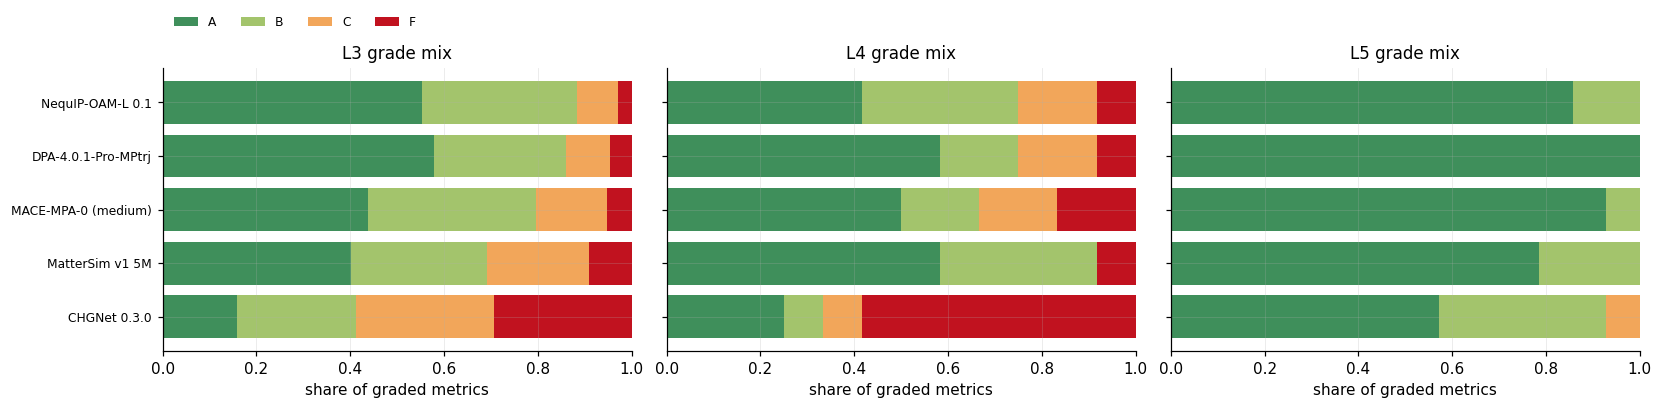

In [15]:
from mlipeval.ranking import load_results

GRADES = ["A", "B", "C", "F"]
rows = []
for k in ORDER:
    for stem, res in load_results(k).items():
        level = stem.split("_")[0]
        if level not in ("L3a", "L3b", "L4", "L5"):
            continue
        for r in res.get("results", []):
            if r.get("grade") in GRADES:
                rows.append({"model": LABELS[k], "level": "L3" if level.startswith("L3") else level,
                             "grade": r["grade"]})
gr = pd.DataFrame(rows)
table = (pd.crosstab([gr.model, gr.level], gr.grade).reindex(columns=GRADES, fill_value=0))
share = table.div(table.sum(axis=1), axis=0)
display(table.assign(n=table.sum(axis=1)))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
palette = {"A": "#3f8f5b", "B": "#a3c46c", "C": "#f2a65a", "F": "#c1121f"}
for ax, level in zip(axes, ("L3", "L4", "L5")):
    sub = share.xs(level, level="level").reindex([LABELS[k] for k in ORDER])
    left = np.zeros(len(sub))
    for g in GRADES:
        ax.barh(np.arange(len(sub)), sub[g], left=left, color=palette[g], label=g)
        left += sub[g].values
    ax.set_yticks(np.arange(len(sub))); ax.set_yticklabels(sub.index, fontsize=8)
    ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("share of graded metrics")
    ax.set_title(f"{level} grade mix")
axes[0].legend(ncol=4, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.1))
plt.show()

## 10. 汇总与结论

In [16]:
rows = []
for rank, k in enumerate(ORDER, 1):
    row = {"rank": rank, "model": LABELS[k],
           "overall": round(ranking.overall[k], 1),
           "L1 gate": "pass" if ranking.gate_open[k] else "closed"}
    for lv in LEVELS:
        s = ranking.level_scores[lv][k]
        row[lv] = round(s, 1) if s is not None else None
    rows.append(row)
display(pd.DataFrame(rows).set_index("rank"))

print("\n分数定义: 100 * (x_best + floor) / (x_i + floor) 逐指标, 再按级别权重加权")
print("级别权重:", ranking.level_weights)
print("\n完整报告: eval/results/RANKING_REPORT.md")
print("机器可读: eval/results/ranking.json")

,model,overall,L1 gate,L0,L1,L2,L3,L4,L5
rank,,,,,,,,,
1,NequIP-OAM-L 0.1,92.3,pass,91.4,97.1,91.4,97.4,89.5,79.6
2,DPA-4.0.1-Pro-MPtrj,86.3,closed,91.9,43.5,87.6,98.0,95.7,93.6
3,MACE-MPA-0 (medium),80.9,pass,63.7,97.2,74.0,82.5,82.8,94.5
4,MatterSim v1 5M,76.2,pass,65.1,90.4,64.1,70.1,100.0,75.0
5,CHGNet 0.3.0,34.9,closed,22.2,28.1,18.7,45.5,52.0,42.7



分数定义: 100 * (x_best + floor) / (x_i + floor) 逐指标, 再按级别权重加权
级别权重: {'L0': 0.2, 'L1': 0.15, 'L2': 0.15, 'L3': 0.25, 'L4': 0.15, 'L5': 0.1}

完整报告: eval/results/RANKING_REPORT.md
机器可读: eval/results/ranking.json


**一句话结论**

（执行后填写。）